# Лабораторная работа 6б. Стохастический градиентный спуск и его модификации

Всё реализовано вручную на `numpy`; производные по параметрам везде вычисляются **численно** (центральные разности, $h=10^{-6}$), как требует задание. Для ускорения все $2p$ возмущённых наборов параметров вычисляются одним векторизованным вызовом.

## Задача 1. Минимум функции методом золотого сечения

$f(z)=1-\tfrac12e^{-10(z-0.65)^2}-0.45e^{-50(z-0.35)^2}$

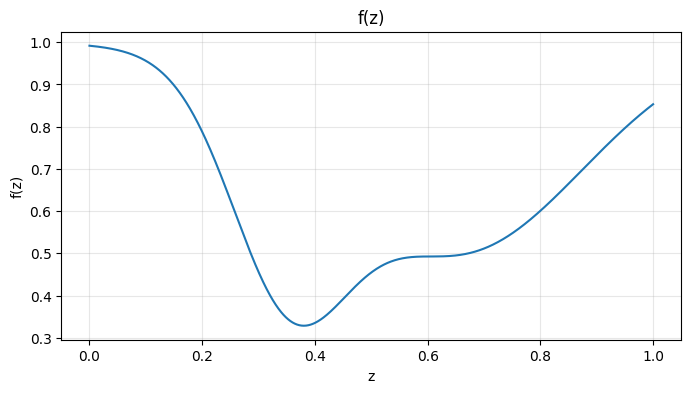

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, time
from scipy.optimize import minimize_scalar
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
f = lambda z: 1 - 0.5*np.exp(-10*(z-0.65)**2) - 0.45*np.exp(-50*(z-0.35)**2)

def golden(f, a, b, tol=1e-10):
    """Метод золотого сечения: на каждом шаге интервал сжимается в 1/φ раз, одно вычисление f на итерацию."""
    g = (np.sqrt(5)-1)/2; c, d = b - g*(b-a), a + g*(b-a); fc, fd = f(c), f(d); it = 0; ev = 2
    while b - a > tol:
        if fc < fd: b, d, fd = d, c, fc; c = b - g*(b-a); fc = f(c)
        else:       a, c, fc = c, d, fd; d = a + g*(b-a); fd = f(d)
        it += 1; ev += 1
    x = (a+b)/2; return x, f(x), it, ev

zz = np.linspace(0, 1, 1000); plt.figure(figsize=(8, 4)); plt.plot(zz, f(zz)); plt.xlabel("z"); plt.ylabel("f(z)"); plt.title("f(z)"); plt.grid(alpha=.3)

In [2]:
rows = []
for name, (a, b) in {"[0, 1] (весь отрезок)": (0, 1), "[0, 0.5] (левая яма)": (0, 0.5), "[0.5, 1] (правая яма)": (0.5, 1)}.items():
    x, fx, it, ev = golden(f, a, b); r = minimize_scalar(f, bounds=(a, b), method="bounded", options={"xatol": 1e-10})
    rows.append(dict(интервал=name, z_min=x, f_min=fx, итераций=it, вычислений_f=ev, z_scipy=r.x, f_scipy=r.fun))
res1 = pd.DataFrame(rows).set_index("интервал"); print(res1.to_string(float_format=lambda v: f"{v:.8f}"))
zg = np.linspace(0, 1, 2_000_001); k = np.argmin(f(zg)); print(f"\nГлобальный минимум по плотной сетке на [0,1]: z = {zg[k]:.6f}, f = {f(zg[k]):.8f}")

                           z_min      f_min  итераций  вычислений_f    z_scipy    f_scipy
интервал                                                                                 
[0, 1] (весь отрезок) 0.38032153 0.32860366        48            50 0.38032153 0.32860366
[0, 0.5] (левая яма)  0.38032153 0.32860366        47            49 0.38032153 0.32860366
[0.5, 1] (правая яма) 0.50000000 0.45464828        47            49 0.50000001 0.45464829

Глобальный минимум по плотной сетке на [0,1]: z = 0.380321, f = 0.32860366


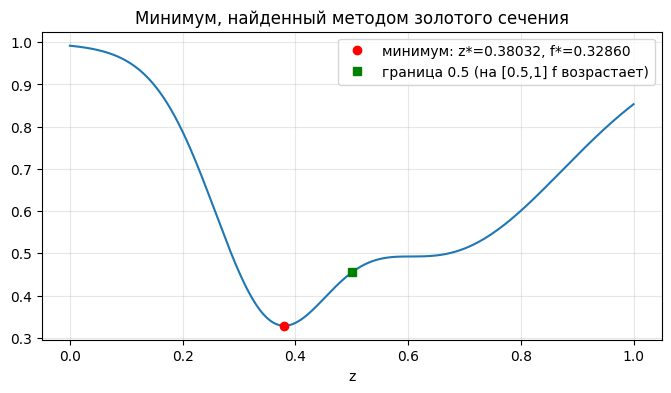

Text(0.5, 1.0, 'Минимум, найденный методом золотого сечения')

In [3]:
xg, fg = golden(f, 0, 1)[:2]
plt.figure(figsize=(8, 4)); plt.plot(zz, f(zz)); plt.plot([xg], [fg], "ro", label=f"минимум: z*={xg:.5f}, f*={fg:.5f}")
plt.plot([0.5], [f(0.5)], "gs", label="граница 0.5 (на [0.5,1] f возрастает)"); plt.legend(); plt.grid(alpha=.3); plt.xlabel("z"); plt.title("Минимум, найденный методом золотого сечения")

**Комментарий.** Хотя слагаемые функции — две гауссианы (центры 0,35 и 0,65), на отрезке $[0;1]$ они сливаются: правая «яма» ($z=0{,}65$, глубина 0,5) лишь образует «плечо» и отдельного локального минимума не создаёт — $f(0{,}65)\approx0{,}495$ выше, чем $f(0{,}5)\approx0{,}455$, а $f(0{,}38)\approx0{,}329$. Поэтому функция унимодальна на $[0;1]$, что и нужно методу золотого сечения. Найден единственный минимум $z^*\approx0{,}38032$, $f^*\approx0{,}32860$; он совпадает с минимумом по плотной сетке (2 млн точек) и с `scipy` (ограниченный метод Брента) до $10^{-8}$. На подотрезке $[0{,}5;1]$ функция монотонно растёт, и метод сходится к левой границе 0,5 (минимум на границе, а не стационарная точка) — наглядное напоминание, что метод ищет минимум **внутри заданной скобки**. Для точности $10^{-10}$ потребовалось ≈ 48 итераций и 50 вычислений $f$: интервал сжимается в $\varphi\approx1{,}618$ раз за итерацию, сходимость линейная.

## Подготовка к задачам 2–5: модели, численные производные, оптимизаторы

In [4]:
X = np.array([0.03,0.19,0.34,0.46,0.78,0.81,1.08,1.18,1.39,1.60,1.65,1.90])
Y = np.array([0.67,0.85,1.05,1.00,1.40,1.50,1.30,1.54,1.55,1.68,1.73,1.60]); n = len(X)
relu = lambda z: np.maximum(z, 0)

def pred(m, W, x):
    """W: (K, p) — K наборов параметров сразу; x: (n,). Возвращает (K, n)."""
    W = np.atleast_2d(W); c = lambda i: W[:, i:i+1]; x = np.asarray(x)[None, :]
    if m == 1: return c(0)*x + c(1)                                                       # w1 x + b1
    if m == 2: return c(0)*x**2 + c(1)*x + c(2)                                           # w1 x² + w2 x + b1
    return relu(c(4)*relu(c(0)*x + c(1)) + c(5)*relu(c(2)*x + c(3)) + c(6))               # порядок: w11,b11,w12,b12,w21,w22,b21
NP = {1: 2, 2: 3, 3: 7}
WMASK = {1: [0], 2: [0, 1], 3: [0, 2, 4, 5]}        # индексы весов (без смещений) — для квадратичного штрафа
NAME = {1: "Модель 1 (линейная)", 2: "Модель 2 (парабола)", 3: "Модель 3 (ReLU-сеть)"}

def total(m, W, x, y, lam=0.0, scale=1.0):
    W = np.atleast_2d(W); return scale*((y - pred(m, W, x))**2).sum(1) + lam*(W[:, WMASK[m]]**2).sum(1)

def numgrad(m, w, x, y, lam, scale, h=1e-6):
    E = h*np.eye(len(w)); return (total(m, w+E, x, y, lam, scale) - total(m, w-E, x, y, lam, scale))/(2*h)

# проверка численного градиента аналитическим (модель 2, потери Σ(y-ŷ)²)
w_t = np.array([0.3, -0.2, 0.5]); A = np.c_[X**2, X, np.ones(n)]; g_an = -2*A.T@(Y - A@w_t)
print("Численный vs аналитический градиент (модель 2): max разница =", np.abs(numgrad(2, w_t, X, Y, 0, 1) - g_an).max())

Численный vs аналитический градиент (модель 2): max разница = 8.918732419260778e-10


In [5]:
def train(m, opt, epochs, batch=None, lr=0.005, lam=0.0, seed=0, mu=0.9, b1=0.9, b2=0.999, w0=None):
    """opt: 'gd' (градиентный спуск; при batch<n — SGD с минибатчами), 'nesterov', 'adam'.
    Потеря минибатча умножается на n/|batch| (несмещённая оценка полной потери). Эпоха = один проход по выборке.
    Возвращает параметры и историю полной (без штрафа) потери Σ(y-ŷ)² по эпохам."""
    B = n if batch is None else batch; rng = np.random.default_rng(seed)
    w = INIT[m].copy() if w0 is None else w0.copy(); v = np.zeros_like(w); s = np.zeros_like(w); t = 0; hist = []
    for ep in range(epochs):
        idx = rng.permutation(n) if B < n else np.arange(n)
        for k in range(0, n, B):
            bi = idx[k:k+B]; sc = n/len(bi); t += 1
            if opt == "gd": w = w - lr*numgrad(m, w, X[bi], Y[bi], lam, sc)
            elif opt == "nesterov":                                       # градиент в точке «заглядывания вперёд»
                g = numgrad(m, w + mu*v, X[bi], Y[bi], lam, sc); v = mu*v - lr*g; w = w + v
            else:
                g = numgrad(m, w, X[bi], Y[bi], lam, sc); v = b1*v + (1-b1)*g; s = b2*s + (1-b2)*g*g
                w = w - lr*(v/(1-b1**t))/(np.sqrt(s/(1-b2**t)) + 1e-8)
        hist.append(total(m, w, X, Y)[0])
    return w, np.array(hist)

def exact(m, lam=0.0):          # точное решение (МНК / ридж) для линейных по параметрам моделей 1, 2
    A = np.c_[X, np.ones(n)] if m == 1 else np.c_[X**2, X, np.ones(n)]
    D = np.zeros(A.shape[1]); D[WMASK[m]] = 1
    w = np.linalg.solve(A.T@A + lam*np.diag(D), A.T@Y); return w, total(m, w, X, Y)[0]

xs = np.linspace(0, 2.0, 300)
def plot_fits(ax, m, ws, labels):
    ax.scatter(X, Y, c="k", zorder=5, label="данные")
    for w, lb in zip(ws, labels): ax.plot(xs, pred(m, w, xs)[0], label=lb)
    ax.set_title(NAME[m]); ax.grid(alpha=.3); ax.set_xlabel("x"); ax.set_ylabel("y"); ax.legend(fontsize=7)
print("Эталон (точное МНК): L1 =", exact(1)[1].round(5), "| L2 =", exact(2)[1].round(5))

Эталон (точное МНК): L1 = 0.19987 | L2 = 0.09088


### Инициализация модели 3

У ReLU-сети функция потерь невыпукла: при неудачном старте нейроны «умирают» (выход ≡ 0), либо сеть застревает в линейном режиме. Проверим 16 случайных инициализаций (Adam, минибатч 4) и возьмём лучшую для всех дальнейших экспериментов (так сравнение методов не зависит от удачи со стартом). Для моделей 1 и 2 (выпуклых) старт — нулевые параметры.

In [6]:
ms = []
for sd in range(16):
    w0 = np.random.default_rng(sd).normal(0, 1, 7); w, h = train(3, "adam", 3000, batch=4, lr=0.01, w0=w0); ms.append((h[-1], sd))
ms.sort(); print("Лучшие 5 (L, seed):", [(round(a, 4), b) for a, b in ms[:5]])
print("Худшие 3:", [(round(a, 3), b) for a, b in ms[-3:]], "| L при нулевом выходе =", round((Y**2).sum(), 3))
print("Доля стартов, закончивших с L > 1 («мёртвая» сеть):", np.mean([a > 1 for a, _ in ms]))
INIT = {1: np.zeros(2), 2: np.zeros(3), 3: np.random.default_rng(ms[0][1]).normal(0, 1, 7)}
print("Выбрана инициализация модели 3 (seed = %d):" % ms[0][1], INIT[3].round(2))

Лучшие 5 (L, seed): [(np.float64(0.0795), 11), (np.float64(0.1272), 9), (np.float64(0.1309), 10), (np.float64(0.2), 6), (np.float64(0.2), 0)]
Худшие 3: [(np.float64(22.323), 7), (np.float64(22.323), 8), (np.float64(22.323), 15)] | L при нулевом выходе = 22.323
Доля стартов, закончивших с L > 1 («мёртвая» сеть): 0.5
Выбрана инициализация модели 3 (seed = 11): [ 0.03  1.36  1.22 -0.51 -0.3  -0.53  0.57]


## Задача 2. Классический (полный) градиентный спуск

Шаг $\varepsilon=0{,}005$, 20 000 итераций (одна итерация = полный проход по выборке).

In [7]:
t0 = time.time(); GD = {m: train(m, "gd", 20000, lr=0.005) for m in (1, 2, 3)}; print("время, с:", round(time.time()-t0, 1))
rows = [dict(модель=NAME[m], параметров=NP[m], L_итог=GD[m][1][-1], L_точное_МНК=(exact(m)[1] if m < 3 else np.nan), w=np.round(GD[m][0], 3)) for m in (1, 2, 3)]
pd.DataFrame(rows).set_index("модель")

время, с: 2.9


,параметров,L_итог,L_точное_МНК,w
модель,,,,
Модель 1 (линейная),2,0.199866,0.199866,"[0.522, 0.826]"
Модель 2 (парабола),3,0.090882,0.090882,"[-0.318, 1.127, 0.649]"
Модель 3 (ReLU-сеть),7,0.199866,NaN,"[0.336, 1.273, 1.27, -0.038, 0.124, 0.378, 0.683]"


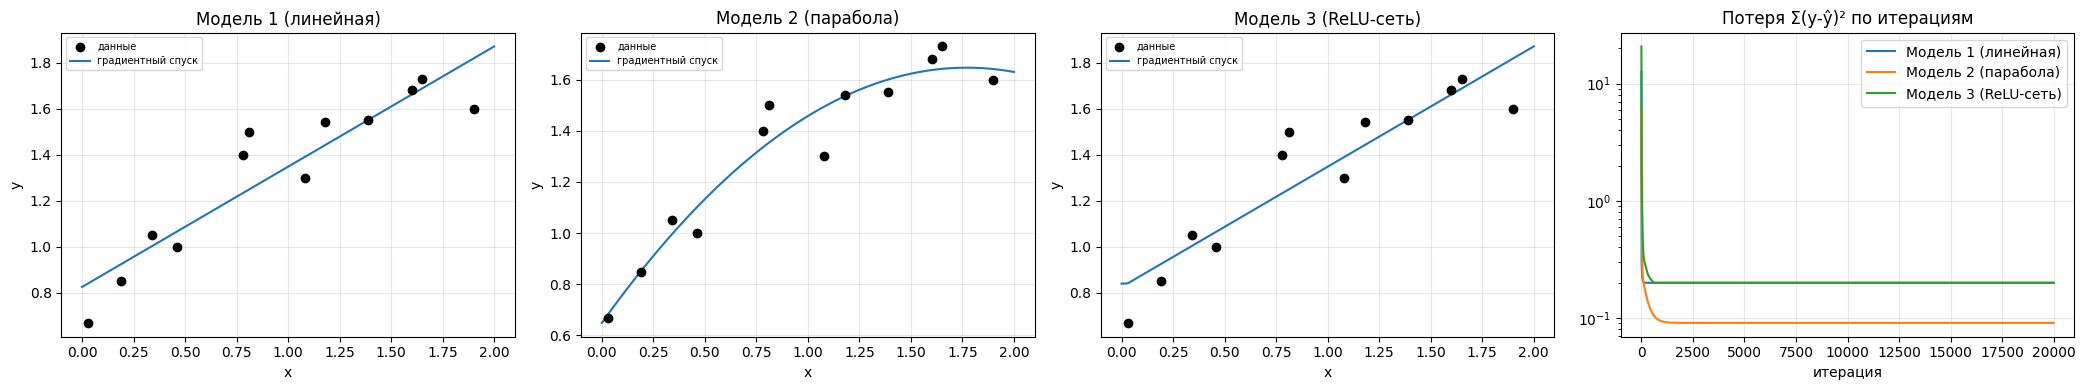

In [8]:
fig, ax = plt.subplots(1, 4, figsize=(21, 4))
for a, m in zip(ax, (1, 2, 3)): plot_fits(a, m, [GD[m][0]], ["градиентный спуск"])
for m in (1, 2, 3): ax[3].semilogy(GD[m][1], label=NAME[m])
ax[3].set_title("Потеря Σ(y-ŷ)² по итерациям"); ax[3].set_xlabel("итерация"); ax[3].legend(); ax[3].grid(alpha=.3); plt.tight_layout()

## Задача 3. Стохастический градиентный спуск с минибатчами

Размеры батча $B\in\{1,2,3,4,6,12\}$ ($B=12$ — полный градиентный спуск). Шаг масштабируется как $\varepsilon_B=0{,}005\,B/12$ (потеря батча умножена на $n/B$, поэтому при малых $B$ градиент шумнее и шаг должен быть меньше), 5000 эпох, одинаковое число проходов по данным.

In [9]:
Bs = [1, 2, 3, 4, 6, 12]; SGD = {}; rows = []
t0 = time.time()
for m in (1, 2, 3):
    for B in Bs:
        w, h = train(m, "gd", 5000, batch=B, lr=0.005*B/12); SGD[(m, B)] = (w, h)
        rows.append(dict(модель=NAME[m], B=B, шагов_за_эпоху=int(np.ceil(n/B)), L_итог=h[-1], L_мин_за_всё_время=h.min(), размах_L_последние_500_эпох=h[-500:].max()-h[-500:].min()))
print("время, с:", round(time.time()-t0, 1)); pd.DataFrame(rows).set_index(["модель", "B"]).round(5)

время, с: 14.9


шагов_за_эпоху   L_итог  L_мин_за_всё_время  размах_L_последние_500_эпох
модель               B                                                                           
Модель 1 (линейная)  1               12  0.19992             0.19987                      0.00015
                     2                6  0.19993             0.19987                      0.00018
                     3                4  0.19990             0.19987                      0.00015
                     4                3  0.19992             0.19987                      0.00023
                     6                2  0.19992             0.19987                      0.00017
                     12               1  0.19987             0.19987                      0.00000
Модель 2 (парабола)  1               12  0.09094             0.09088                      0.00066
                     2                6  0.09095             0.09088                      0.00076
                     3                4  0.09091             0.09088                      0.00055
                     4                3  0.09095             0.09088                      0.00076
                     6                2  0.09091             0.09088                      0.00057
                     12               1  0.09088             0.09088                      0.00000
Модель 3 (ReLU-сеть) 1               12  0.20080             0.19987                      0.00190
                     2                6  0.20095             0.19987                      0.00190
                     3                4  0.20062             0.19987                      0.00192
                     4                3  0.20090             0.19987                      0.00247
                     6                2  0.20092             0.19987                      0.00212
                     12               1  0.19987             0.19987                      0.00000

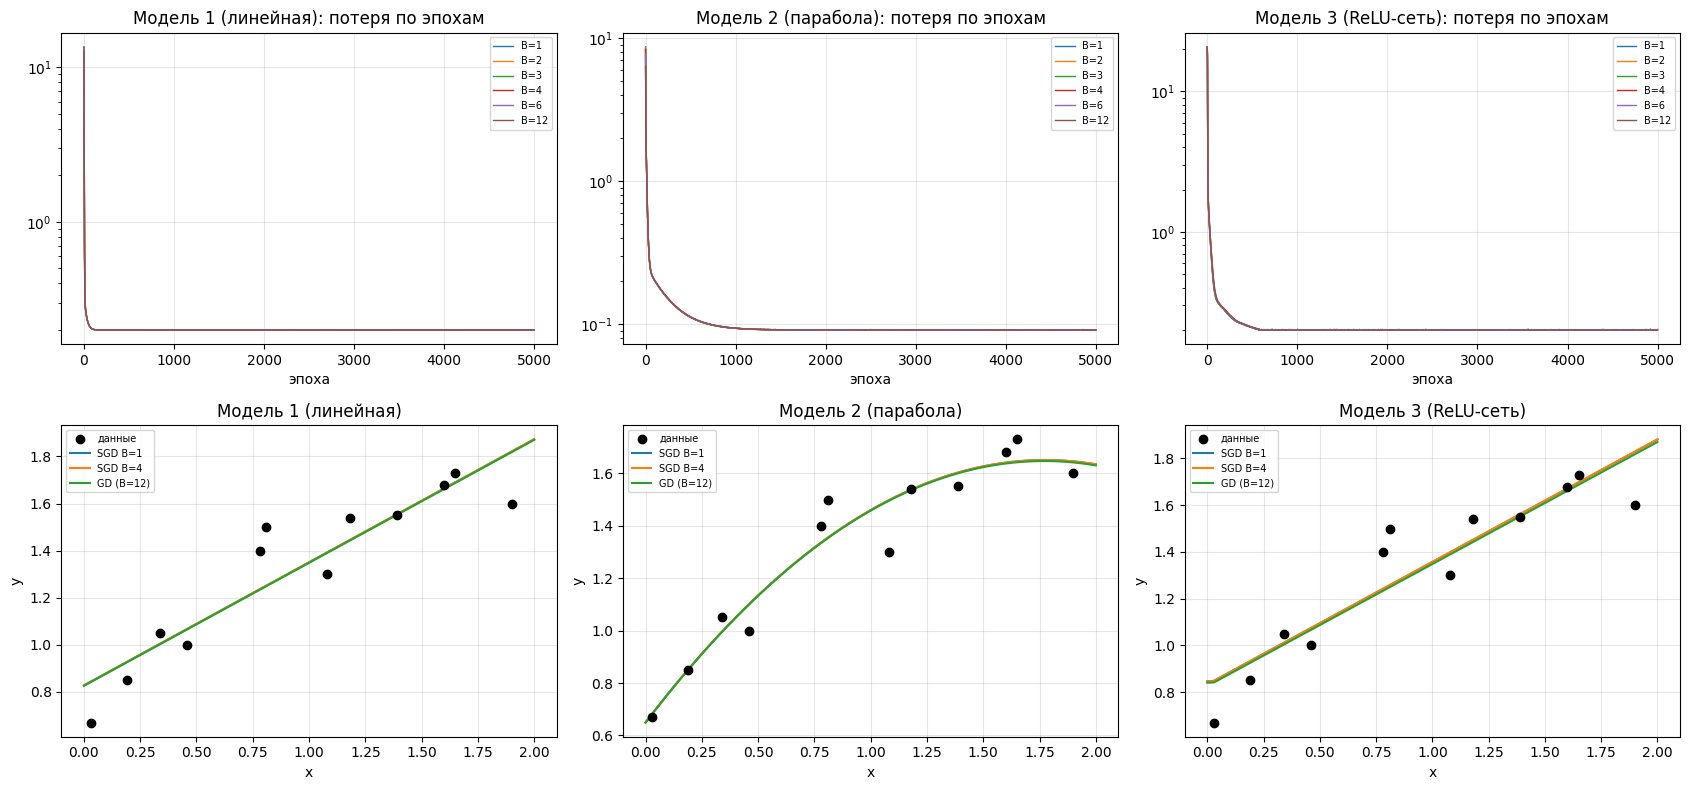

In [10]:
fig, ax = plt.subplots(2, 3, figsize=(17, 8))
for j, m in enumerate((1, 2, 3)):
    for B in Bs: ax[0, j].semilogy(SGD[(m, B)][1], label=f"B={B}", lw=1)
    ax[0, j].set_title(NAME[m] + ": потеря по эпохам"); ax[0, j].set_xlabel("эпоха"); ax[0, j].legend(fontsize=7); ax[0, j].grid(alpha=.3)
    plot_fits(ax[1, j], m, [SGD[(m, B)][0] for B in (1, 4, 12)], ["SGD B=1", "SGD B=4", "GD (B=12)"])
plt.tight_layout()

## Задача 4. Импульс Нестерова и Adam

Минибатч $B=4$, 5000 эпох. Параметры: Нестеров — $\mu=0{,}9$, $\varepsilon=5\cdot10^{-4}$; Adam — $\varepsilon=0{,}01$, $\beta_1=0{,}9$, $\beta_2=0{,}999$. Сравниваем с GD (задача 2) и SGD $B=4$ (задача 3).

In [11]:
t0 = time.time(); CMP = {}
for m in (1, 2, 3):
    CMP[(m, "GD (полный)")] = GD[m]
    CMP[(m, "SGD B=4")] = SGD[(m, 4)]
    CMP[(m, "Нестеров B=4")] = train(m, "nesterov", 5000, batch=4, lr=5e-4)
    CMP[(m, "Adam B=4")] = train(m, "adam", 5000, batch=4, lr=0.01)
print("время, с:", round(time.time()-t0, 1))
methods = ["GD (полный)", "SGD B=4", "Нестеров B=4", "Adam B=4"]
rows = []
for m in (1, 2, 3):
    best = min(CMP[(m, k)][1][-1] for k in methods)
    for k in methods:
        h = CMP[(m, k)][1]; hit = np.where(h <= 1.05*best)[0]
        rows.append(dict(модель=NAME[m], метод=k, L_итог=h[-1], **{"эпох до 1.05·L_лучш": (int(hit[0])+1 if len(hit) else np.nan)}, размах_L_последние_500=h[-500:].max()-h[-500:].min()))
pd.DataFrame(rows).set_index(["модель", "метод"]).round(5)

время, с: 4.1


L_итог  эпох до 1.05·L_лучш  размах_L_последние_500
модель               метод                                                             
Модель 1 (линейная)  GD (полный)   0.19987                 68.0                 0.00000
                     SGD B=4       0.19992                 68.0                 0.00023
                     Нестеров B=4  0.20010                 24.0                 0.00077
                     Adam B=4      0.20020                121.0                 0.00228
Модель 2 (парабола)  GD (полный)   0.09088                883.0                 0.00000
                     SGD B=4       0.09095                866.0                 0.00076
                     Нестеров B=4  0.09094                288.0                 0.00126
                     Adam B=4      0.09089                607.0                 0.00639
Модель 3 (ReLU-сеть) GD (полный)   0.19987                  NaN                 0.00000
                     SGD B=4       0.20090                  NaN                 0.00247
                     Нестеров B=4  0.20003                  NaN                 0.00318
                     Adam B=4      0.07890                594.0                 0.01434

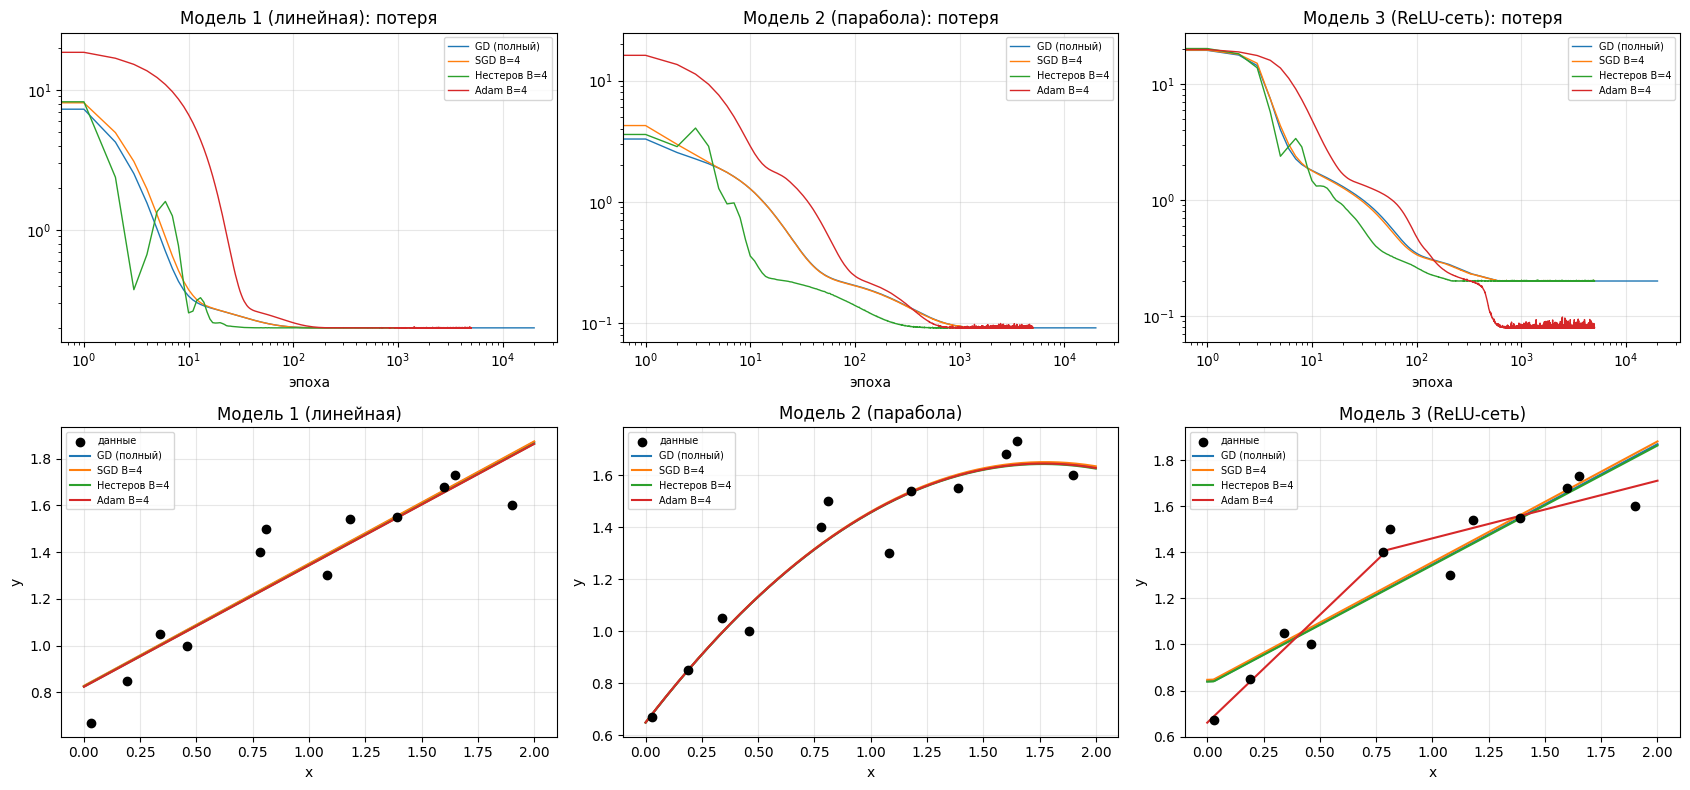

In [12]:
fig, ax = plt.subplots(2, 3, figsize=(17, 8))
for j, m in enumerate((1, 2, 3)):
    for k in methods: ax[0, j].semilogy(CMP[(m, k)][1], label=k, lw=1)
    ax[0, j].set_xscale("log"); ax[0, j].set_title(NAME[m] + ": потеря"); ax[0, j].set_xlabel("эпоха"); ax[0, j].legend(fontsize=7); ax[0, j].grid(alpha=.3)
    plot_fits(ax[1, j], m, [CMP[(m, k)][0] for k in methods], methods)
plt.tight_layout()

### Задача 4 (продолжение): Нестеров и Adam при разных размерах батча

Как и в задаче 3, перебираем $B\in\{1,2,3,4,6,12\}$ ($B=12$ — полный батч), 5000 эпох. Шаг Нестерова масштабируем пропорционально батчу, как в задаче 3: $\varepsilon_B=1{,}25\cdot10^{-4}B$ (при $B=4$ это прежние $5\cdot10^{-4}$), $\mu=0{,}9$. У Adam шаг $\varepsilon=0{,}01$ одинаков для всех $B$ (Adam нормирует градиент, поэтому масштаб потери на шаг не влияет).

In [13]:
t0 = time.time(); BO = {}; rows = []
for opt, nm, lr_fn in [("nesterov", "Нестеров", lambda B: 1.25e-4*B), ("adam", "Adam", lambda B: 0.01)]:
    for m in (1, 2, 3):
        for B in Bs:
            w, h = train(m, opt, 5000, batch=B, lr=lr_fn(B)); BO[(nm, m, B)] = (w, h)
print("время, с:", round(time.time()-t0, 1))
for m in (1, 2, 3):
    best = min([BO[(nm, m, B)][1][-1] for nm in ("Нестеров", "Adam") for B in Bs] + [SGD[(m, B)][1][-1] for B in Bs])
    for nm in ("Нестеров", "Adam"):
        for B in Bs:
            h = BO[(nm, m, B)][1]; hit = np.where(h <= 1.05*best)[0]
            rows.append({"модель": NAME[m], "метод": nm, "B": B, "L_итог": h[-1], "L_мин": h.min(), "эпох до 1.05·L_лучш": (int(hit[0])+1 if len(hit) else np.nan), "размах_L_последние_500": h[-500:].max()-h[-500:].min()})
pd.DataFrame(rows).set_index(["модель", "метод", "B"]).round(5)

время, с: 34.0


L_итог    L_мин  эпох до 1.05·L_лучш  размах_L_последние_500
модель               метод    B                                                                
Модель 1 (линейная)  Нестеров 1   0.19990  0.19987                 23.0                 0.00447
                              2   0.19998  0.19987                 23.0                 0.00245
                              3   0.20008  0.19987                 22.0                 0.00178
                              4   0.20010  0.19987                 24.0                 0.00077
                              6   0.19999  0.19987                 28.0                 0.00034
                              12  0.19987  0.19987                 29.0                 0.00000
                     Adam     1   0.20040  0.19987                 27.0                 0.02399
                              2   0.19987  0.19987                 58.0                 0.00669
                              3   0.20004  0.19987                 88.0                 0.00543
                              4   0.20020  0.19987                121.0                 0.00228
                              6   0.20000  0.19987                180.0                 0.00096
                              12  0.19987  0.19987                362.0                 0.00000
Модель 2 (парабола)  Нестеров 1   0.09116  0.09088                285.0                 0.00613
                              2   0.09089  0.09088                292.0                 0.00229
                              3   0.09091  0.09088                288.0                 0.00181
                              4   0.09094  0.09088                288.0                 0.00126
                              6   0.09098  0.09088                289.0                 0.00061
                              12  0.09088  0.09088                288.0                 0.00000
                     Adam     1   0.09144  0.09088                209.0                 0.08275
                              2   0.09536  0.09088                354.0                 0.02615
                              3   0.09114  0.09088                489.0                 0.00766
                              4   0.09089  0.09088                607.0                 0.00639
                              6   0.09096  0.09088                874.0                 0.00388
                              12  0.09088  0.09088               1635.0                 0.00000
Модель 3 (ReLU-сеть) Нестеров 1   0.19996  0.19987                  NaN                 0.01222
                              2   0.19988  0.19987                  NaN                 0.00733
                              3   0.19991  0.19987                  NaN                 0.00552
                              4   0.20003  0.19987                  NaN                 0.00318
                              6   0.20012  0.19987                  NaN                 0.00163
                              12  0.19987  0.19987                  NaN                 0.00000
                     Adam     1   0.08027  0.07888                179.0                 0.11817
                              2   0.09970  0.07881                300.0                 0.04392
                              3   0.07888  0.07880                450.0                 0.02034
                              4   0.07890  0.07880                594.0                 0.01434
                              6   0.07911  0.07879                662.0                 0.00773
                              12  0.19987  0.19987                  NaN                 0.00000

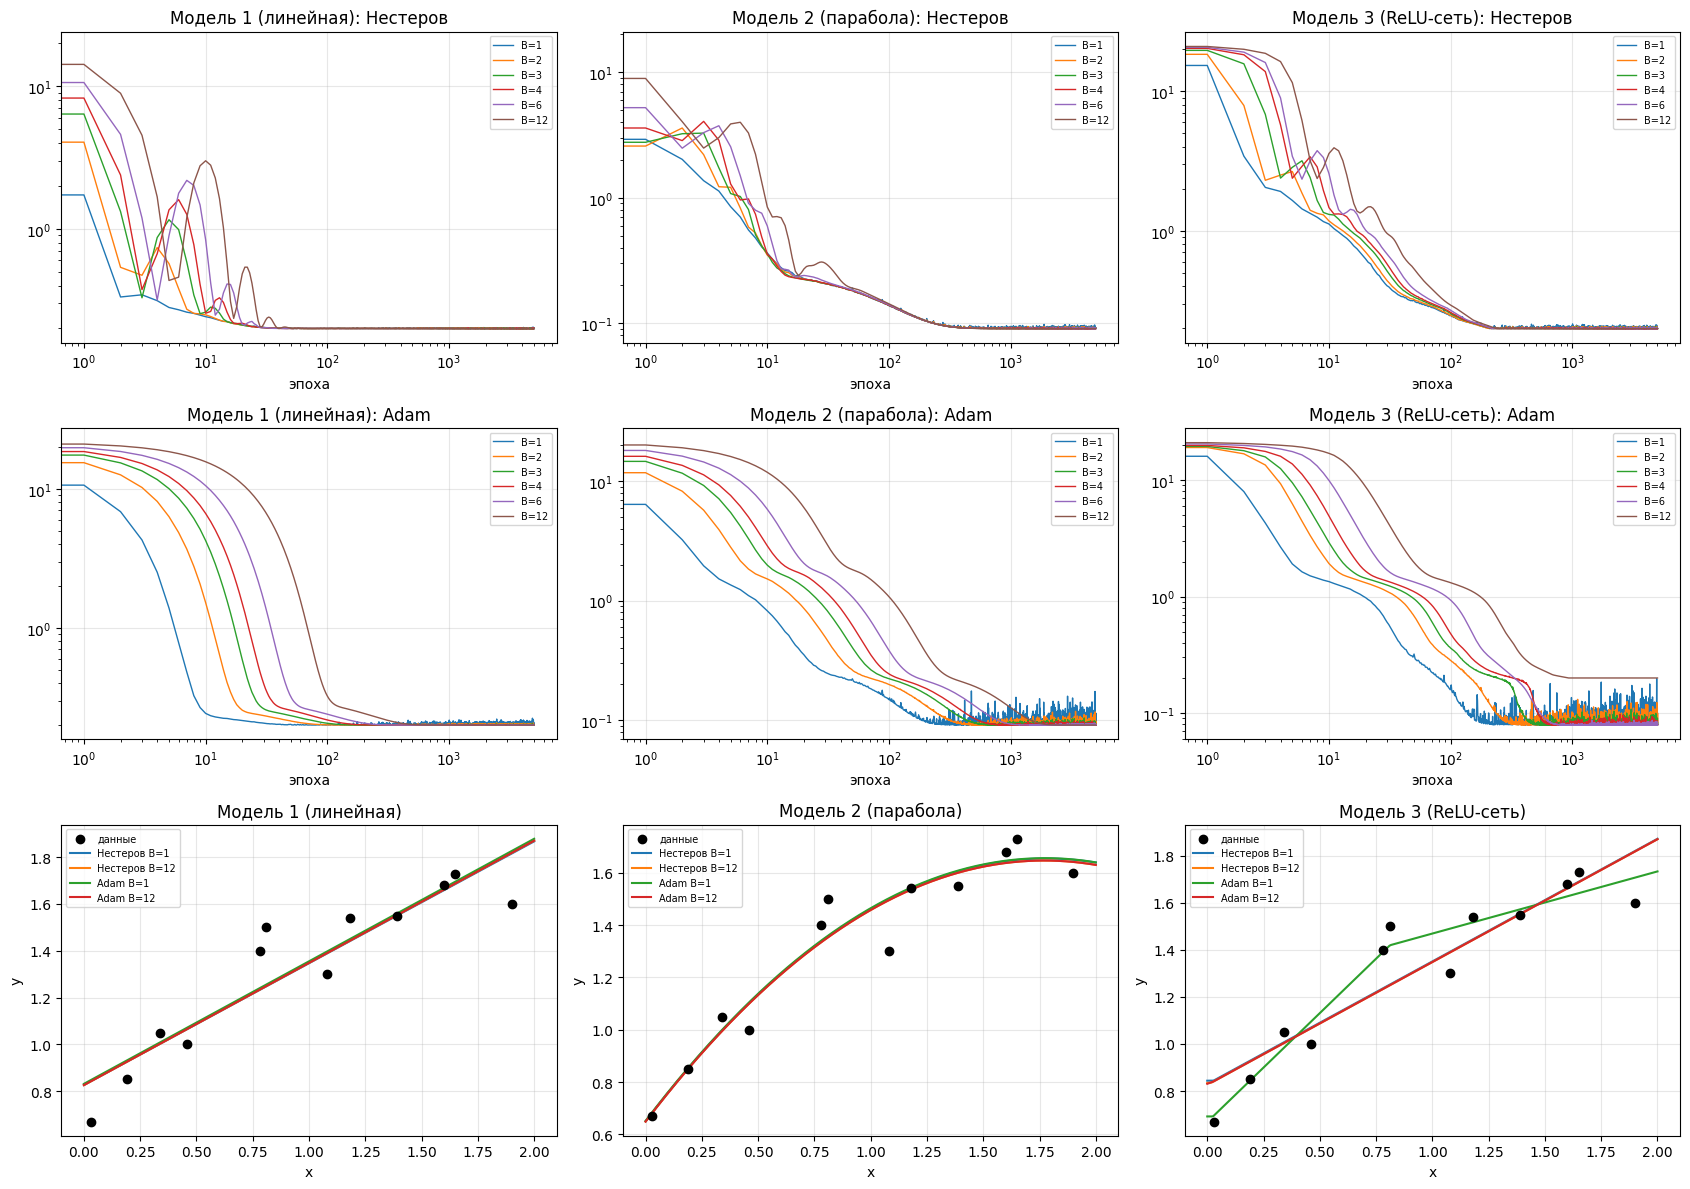

In [14]:
fig, ax = plt.subplots(3, 3, figsize=(17, 12))
for j, m in enumerate((1, 2, 3)):
    for r, nm in enumerate(("Нестеров", "Adam")):
        for B in Bs: ax[r, j].semilogy(BO[(nm, m, B)][1], label=f"B={B}", lw=1)
        ax[r, j].set_xscale("log"); ax[r, j].set_title(f"{NAME[m]}: {nm}"); ax[r, j].set_xlabel("эпоха"); ax[r, j].legend(fontsize=7); ax[r, j].grid(alpha=.3)
    plot_fits(ax[2, j], m, [BO[(nm, m, B)][0] for nm in ("Нестеров", "Adam") for B in (1, 12)], [f"{nm} B={B}" for nm in ("Нестеров", "Adam") for B in (1, 12)])
plt.tight_layout()

## Задача 5*. Квадратичный штраф (L2-регуляризация)

Минимизируем $\sum_i(y_i-\hat y(x_i))^2+\lambda\sum w^2$ (штраф только на веса, смещения не штрафуются). Для моделей 1 и 2 есть точное решение (ридж-регрессия) — используем как эталон. Те же четыре метода и те же настройки, что в задачах 2–4.

In [15]:
lams = [0.0, 0.01, 0.1, 1.0]; setups = {"GD (полный)": dict(opt="gd", epochs=20000, lr=0.005), "SGD B=4": dict(opt="gd", epochs=5000, batch=4, lr=0.005*4/12),
    "Нестеров B=4": dict(opt="nesterov", epochs=5000, batch=4, lr=5e-4), "Adam B=4": dict(opt="adam", epochs=5000, batch=4, lr=0.01)}
t0 = time.time(); REG = {}; rows = []
for m in (1, 2, 3):
    for lam in lams:
        for k, kw in setups.items():
            w, h = train(m, lam=lam, **kw); REG[(m, lam, k)] = (w, h)
            rows.append(dict(модель=NAME[m], λ=lam, метод=k, L_данные=h[-1], L_штраф_полная=total(m, w, X, Y, lam)[0], норма_весов=np.linalg.norm(w[WMASK[m]])))
print("время, с:", round(time.time()-t0, 1))
reg_df = pd.DataFrame(rows); reg_df.set_index(["модель", "λ", "метод"]).round(4)

время, с: 34.4


L_данные  L_штраф_полная  норма_весов
модель               λ    метод                                              
Модель 1 (линейная)  0.00 GD (полный)     0.1999          0.1999       0.5222
                          SGD B=4         0.1999          0.1999       0.5228
                          Нестеров B=4    0.2001          0.2001       0.5197
                          Adam B=4        0.2002          0.2002       0.5196
                     0.01 GD (полный)     0.1999          0.2026       0.5210
                          SGD B=4         0.1999          0.2026       0.5216
                          Нестеров B=4    0.2001          0.2028       0.5185
                          Adam B=4        0.2002          0.2029       0.5183
                     0.10 GD (полный)     0.2005          0.2265       0.5100
                          SGD B=4         0.2005          0.2266       0.5106
                          Нестеров B=4    0.2010          0.2267       0.5076
                          Adam B=4        0.2011          0.2268       0.5074
                     1.00 GD (полный)     0.2425          0.4198       0.4211
                          SGD B=4         0.2416          0.4198       0.4221
                          Нестеров B=4    0.2439          0.4199       0.4196
                          Adam B=4        0.2447          0.4201       0.4188
Модель 2 (парабола)  0.00 GD (полный)     0.0909          0.0909       1.1708
                          SGD B=4         0.0909          0.0909       1.1721
                          Нестеров B=4    0.0909          0.0909       1.1711
                          Adam B=4        0.0909          0.0909       1.1712
                     0.01 GD (полный)     0.0914          0.1040       1.1225
                          SGD B=4         0.0915          0.1041       1.1245
                          Нестеров B=4    0.0915          0.1041       1.1232
                          Adam B=4        0.0914          0.1040       1.1233
                     0.10 GD (полный)     0.1192          0.1870       0.8239
                          SGD B=4         0.1185          0.1873       0.8290
                          Нестеров B=4    0.1189          0.1872       0.8262
                          Adam B=4        0.1188          0.1871       0.8261
                     1.00 GD (полный)     0.2907          0.3778       0.2951
                          SGD B=4         0.2890          0.3784       0.2990
                          Нестеров B=4    0.2913          0.3781       0.2947
                          Adam B=4        0.2919          0.3782       0.2938
Модель 3 (ReLU-сеть) 0.00 GD (полный)     0.1999          0.1999       1.3729
                          SGD B=4         0.2009          0.2009       1.3215
                          Нестеров B=4    0.2000          0.2000       1.2581
                          Adam B=4        0.0789          0.0789       2.1627
                     0.01 GD (полный)     0.1999          0.2103       1.0199
                          SGD B=4         0.2006          0.2123       1.0811
                          Нестеров B=4    0.2001          0.2105       1.0195
                          Adam B=4        0.1999          0.2103       1.0194
                     0.10 GD (полный)     0.2023          0.3019       0.9982
                          SGD B=4         0.2026          0.3026       0.9996
                          Нестеров B=4    0.2027          0.3021       0.9968
                          Adam B=4        0.2026          0.3020       0.9970
                     1.00 GD (полный)     0.4401          1.0041       0.7510
                          SGD B=4         0.4339          1.0044       0.7553
                          Нестеров B=4    0.4392          1.0043       0.7517
                          Adam B=4        0.4413          1.0044       0.7504

In [16]:
# Сводка: эффект штрафа (по методу Adam) + точное ридж-решение для моделей 1 и 2
summ = reg_df[reg_df["метод"] == "Adam B=4"].set_index(["модель", "λ"])[["L_данные", "норма_весов"]].copy()
summ["L_данные (ридж, точно)"] = [exact(m, lam)[1] if m < 3 else np.nan for (nm, lam) in summ.index for m in [[k for k, v in NAME.items() if v == nm][0]]]
summ["норма_весов (ридж, точно)"] = [np.linalg.norm(exact(m, lam)[0][WMASK[m]]) if m < 3 else np.nan for (nm, lam) in summ.index for m in [[k for k, v in NAME.items() if v == nm][0]]]
summ.round(4)

L_данные  норма_весов  L_данные (ридж, точно)  норма_весов (ридж, точно)
модель               λ                                                                             
Модель 1 (линейная)  0.00    0.2002       0.5196                  0.1999                     0.5222
                     0.01    0.2002       0.5183                  0.1999                     0.5210
                     0.10    0.2011       0.5074                  0.2005                     0.5100
                     1.00    0.2447       0.4188                  0.2425                     0.4211
Модель 2 (парабола)  0.00    0.0909       1.1712                  0.0909                     1.1708
                     0.01    0.0914       1.1233                  0.0914                     1.1225
                     0.10    0.1188       0.8261                  0.1192                     0.8239
                     1.00    0.2919       0.2938                  0.2907                     0.2951
Модель 3 (ReLU-сеть) 0.00    0.0789       2.1627                     NaN                        NaN
                     0.01    0.1999       1.0194                     NaN                        NaN
                     0.10    0.2026       0.9970                     NaN                        NaN
                     1.00    0.4413       0.7504                     NaN                        NaN

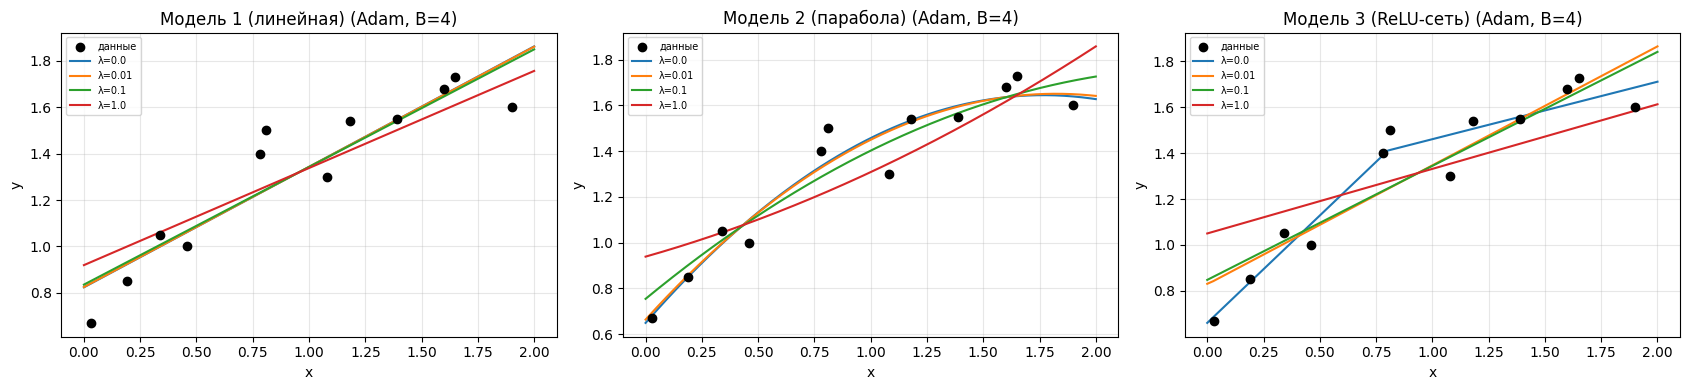

метод,Adam B=4,GD (полный),SGD B=4,Нестеров B=4
модель,,,,
Модель 1 (линейная),0.4201,0.4198,0.4198,0.4199
Модель 2 (парабола),0.3782,0.3778,0.3784,0.3781
Модель 3 (ReLU-сеть),1.0044,1.0041,1.0044,1.0043


In [17]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
for a, m in zip(ax, (1, 2, 3)): plot_fits(a, m, [REG[(m, lam, "Adam B=4")][0] for lam in lams], [f"λ={l}" for l in lams]); a.set_title(NAME[m] + " (Adam, B=4)")
plt.tight_layout()
# разброс методов при λ=1: сходятся ли к одному решению?
reg_df[reg_df["λ"] == 1.0].pivot(index="модель", columns="метод", values="L_штраф_полная").round(4)

## Общие выводы по задачам 2–5

**Задача 2 (полный GD).** Для моделей 1 и 2, выпуклых по параметрам, градиентный спуск с численными производными приходит к точному МНК-решению: $L=0{,}19987$ и $0{,}09088$ (совпадение с эталоном до 5 знаков; численный градиент отличается от аналитического на $\sim10^{-9}$). Парабола подходит заметно лучше прямой (данные выходят на плато). Для ReLU-сети (модель 3, невыпуклая) результат определяется стартом: из 16 случайных инициализаций половина закончила с $L=22{,}3$ (оба нейрона «умерли», выход ≡ 0), несколько остановились на $L\approx0{,}2$ (сеть работает в линейном режиме и просто воспроизводит прямую), лучшая дала $L\approx0{,}08$. Даже с лучшим стартом **полный GD остаётся на «линейном» плато $L=0{,}19987$** — это локальный минимум/плато, а не лучшее, на что способна сеть.

**Задача 3 (SGD с минибатчами).** При всех $B\in\{1,2,3,4,6,12\}$ достигаются те же значения потери, что и у полного GD: для моделей 1–2 — в пределах $\sim10^{-4}$ и $\sim6\cdot10^{-5}$ от оптимума, для модели 3 — те же $\approx0{,}20$. Из-за постоянного шага SGD не сходится точно, а колеблется вокруг минимума (размах потери за последние 500 эпох $\sim10^{-4}$–$10^{-3}$ против нуля у GD), причём из-за пропорционального масштабирования шага $\varepsilon_B\propto B$ уровень шума при разных $B$ получился одного порядка. Преимущество малых батчей — в числе обновлений на эпоху ($12$ при $B=1$ против одного при $B=12$) и в дешёвом шаге на больших данных; на выборке из 12 точек этот выигрыш неощутим, а шум никак не помогает выбраться из линейного плато модели 3. Чтобы SGD сошёлся точно, шаг нужно уменьшать по ходу обучения.

**Задача 4 (Нестеров, Adam).** Сравнение при $B=4$ по числу эпох до достижения $1{,}05L_{\text{лучш}}$: модель 1 — Нестеров 24, GD и SGD 68, Adam 121; модель 2 — Нестеров 288, Adam 607, SGD 866, GD 883. Импульс Нестерова ускоряет сходимость в 3 раза на плохо обусловленной задаче (парабола, где $x$, $x^2$ и 1 сильно коррелированы), Adam в 1,5 раза. Цена — большие колебания в конце при постоянном шаге: размах $L$ у Adam $0{,}002$–$0{,}014$, у Нестерова $\approx0{,}001$–$0{,}003$, у SGD $\le0{,}0025$ — для чистой сходимости к минимуму требуется убывающий шаг. Для модели 3 **только Adam выбрался из линейного плато** ($L=0{,}0789$ — лучше, чем у параболы, $0{,}0909$), тогда как GD, SGD и Нестеров остались на $0{,}200$: покоординатная нормировка шага у Adam эффективно увеличивает шаг по параметрам с малым градиентом. Оговорка: это результат одного запуска и одной инициализации без индивидуальной настройки гиперпараметров; вывод «Adam лучше» нужно подтверждать на нескольких стартах.

**Задача 4, перебор батчей ($B\in\{1,2,3,4,6,12\}$ для Нестерова и Adam).** *Нестеров* (шаг $\propto B$): число эпох до $1{,}05L_{\text{лучш}}$ практически не зависит от $B$ (модель 1: 22–29, модель 2: 285–292), т. е. прогресс за эпоху такой же, как у полного батча, а колебания в конце растут с уменьшением батча (размах $L$ за последние 500 эпох, модель 2: от 0 при $B=12$ до $0{,}006$ при $B=1$). *Adam* (постоянный шаг 0,01): чем меньше батч, тем быстрее по эпохам (модель 2: 1635 эпох при $B=12$ против 209 при $B=1$, так как шагов за эпоху больше), но тем сильнее шум: размах $L$ при $B=1$ достигает $0{,}024$ (модель 1), $0{,}083$ (модель 2), $0{,}118$ (модель 3), а итоговая потеря при малых $B$ может быть хуже минимума (модель 2: $0{,}0954$ при $B=2$). Для сходимости с малыми батчами Adam нужен убывающий шаг. В модели 3 интересное наблюдение: **Adam с полным батчем ($B=12$) остался на линейном плато ($L=0{,}1999$), а с минибатчами $B=1\ldots6$ вышел на $L\approx0{,}079$** — шум минибатчей, по-видимому, помогает покинуть плато (при $B=2$ итоговая $L=0{,}0997$ из-за шума, но минимум за время обучения $0{,}0788$); Нестеров остаётся на плато при любом $B$. Это наблюдение по одному начальному приближению; обобщать его без повторных запусков нельзя.

**Задача 5* (квадратичный штраф).** Рост $\lambda$ монотонно уменьшает норму весов и ухудшает подгонку данных: линейная модель — $L_{\text{данные}}$ от 0,200 до 0,243 при $\lambda=1$; парабола — от 0,091 до 0,291, норма весов от 1,17 до 0,30 (парабола «распрямляется»); ReLU-сеть при $\lambda=1$ недообучена ($L=0{,}44$). Все четыре метода дают практически одинаковые решения при каждом $\lambda$ (разброс полной штрафованной потери $\sim10^{-3}$), а для моделей 1–2 решения совпадают с точной ридж-регрессией (см. сводную таблицу). Штраф делает задачу «лучше обусловленной» — различия между методами сходимости почти исчезают. Для модели 3 штраф уже при $\lambda=0{,}01$ лишил Adam найденного им лучшего решения (его норма весов 2,16 против ≈1,0 на линейном плато), и все методы сошлись в одно решение с $L\approx0{,}20$: регуляризация подавляет «изгиб», который даёт выигрыш на обучающих данных. Так как контрольной выборки нет (12 точек), нельзя утверждать, что штраф улучшает обобщение; он лишь меняет компромисс между точностью подгонки и сложностью модели (смещение–дисперсия), что полезно при малой выборке и для устойчивости экстраполяции.

## Приложение. Использование генеративного ИИ (промт)

Задание выполнено с помощью Claude (Anthropic). Промт пользователя:

> Можешь еще эти лаб работы сделать пожалуйста
> (к промту были приложены файлы lab6a_1.pdf и lab6b_1.pdf; ранее в этом же диалоге: «Сделай эти две лаб работы. На выходе должно быть два notebook ... Если будете пользоваться, приложите к отчёту промты. ... Мне надо чтобы ты сделал все за меня ... Уложись в рамках лимита пожалуйста»)